In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import data

In [2]:
dataset = "UK"

In [3]:
path = {"UK": "", "HKJC": "hkjc-"}[dataset]

events = pd.read_parquet(f"data/{path}events.parquet")
races = pd.read_parquet(f"data/{path}races.parquet")
runners = pd.read_parquet(f"data/{path}runners.parquet")

In [4]:
events

,location,event_date
event_id,,
1824,Bev,2019-09-24
3516,ChelmC,2019-09-24
11890,Ling,2019-09-24
21095,Warw,2019-09-24
14768,Newcastle,2026-01-10
...,...,...
13190,Muss,2017-05-04
896,Ayr,2021-08-09
17352,Ripon,2021-08-09


In [5]:
races

,race_type,race_time,distance_f,event_id,race_no
race_id,,,,,
162764294,Hcap,2019-09-24 15:05:00,7,1824,3
162764320,Hcap,2019-09-24 17:45:00,10,1824,8
162764284,Nov Stks,2019-09-24 14:00:00,5,1824,1
162764331,Nov Stks,2019-09-24 17:25:00,7,3516,2
162764361,Hcap,2019-09-24 20:30:00,14,3516,8
...,...,...,...,...,...
186160695,Nov Stks,2021-08-09 15:35:00,7,896,4
186161070,Hcap,2021-08-09 19:55:00,5,17352,5
186161164,App Hcap,2021-08-09 17:35:00,6,22091,2


In [6]:
runners

,race_id,selection_name,win_lose,bsp,implied_odds,ppwap,morningwap,ppmax,ppmin,ipmax,ipmin,morningtradedvol,pptradedvol,iptradedvol
selection_id,,,,,,,,,,,,,,
8709395,162764294,Zylan,False,23.000000,0.043478,18.397112,10.189857,22.00,9.24,1000.0,12.00,642.739990,13388.459961,1743.660034
20377712,162764320,Major Snugfit,False,7.837297,0.127595,7.288927,7.290506,9.40,6.00,1000.0,2.90,1088.199951,58811.339844,7166.410156
24209475,162764284,Bosuns Chair,False,150.000000,0.006667,156.691589,90.800003,300.00,42.00,1000.0,21.00,65.540001,2000.260010,508.010010
24209478,162764284,Dancinginthesand,False,32.000000,0.031250,24.183567,22.995310,34.00,19.50,1000.0,8.60,277.100006,6302.540039,1921.500000
24148082,162764331,Taamer,False,6.200000,0.161290,7.027211,8.440805,9.60,5.80,1000.0,4.30,631.780029,32564.160156,4578.720215
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40484789,186161169,Alyas Gold Award,False,7.380804,0.135487,7.965647,6.534649,10.50,7.00,1000.0,7.20,615.000000,33865.320312,4295.209961
40262716,186161169,Dansemai,False,17.441746,0.057334,19.368006,40.297195,37.57,16.50,1000.0,5.50,24.900000,10423.820312,2537.709961
35415057,186161205,Chase That Dream,False,4.963830,0.201457,3.770604,3.324620,5.60,3.00,1000.0,3.65,18485.019531,115489.703125,5235.740234


## Prep Data

### Normalise Probabilities

In [7]:
book_pct = runners.groupby("race_id").implied_odds.sum()
runners["normalised_odds"] = runners.implied_odds / runners.race_id.map(book_pct)

# Metrics

- $f_t$ -> forecast
- $o_t$ -> outcome (binary)

## Brier Score

For $N$ observations:

$$BS = \frac{1}{N}\sum_{t=1}^N (f_t - o_t)^2$$

In [8]:
runners["brier"] = np.square(runners.normalised_odds - runners.win_lose)

In [9]:
races["brier"] = runners.groupby("race_id").brier.mean()

## Log Loss

For a single race with $N$ runners:

$$L = - \sum_{i=1}^N o_i \ln(f_i)$$

Because for all losing horses $o = 0$, this can be simplified to:
$$ L = - \ln(f_{winner}) $$

In [10]:
runners["log_loss"] = (-np.log(runners.normalised_odds) * runners.win_lose)

In [11]:
races["log_loss"] = runners.groupby("race_id").log_loss.max()

# Categories

In [106]:
vol=pd.qcut(races.join(runners.groupby("race_id").pptradedvol.sum()).pptradedvol, q=100)

categories = [
    ("Race Number", races[races.race_no < 9].groupby("race_no")),
    ("Distance (Furlongs)", races.groupby("distance_f")),
    ("Hour of Day", races.groupby(races.race_time.dt.hour)),
    ("Pre-play Trade Volume", races.join(vol).groupby("pptradedvol", observed=True)),
    ("Race Type", races.groupby("race_type")),
    ("Location", races.join(events[["location"]], on="event_id").groupby("location"))
]

# Analyse

Text(0, 0.5, 'Count')

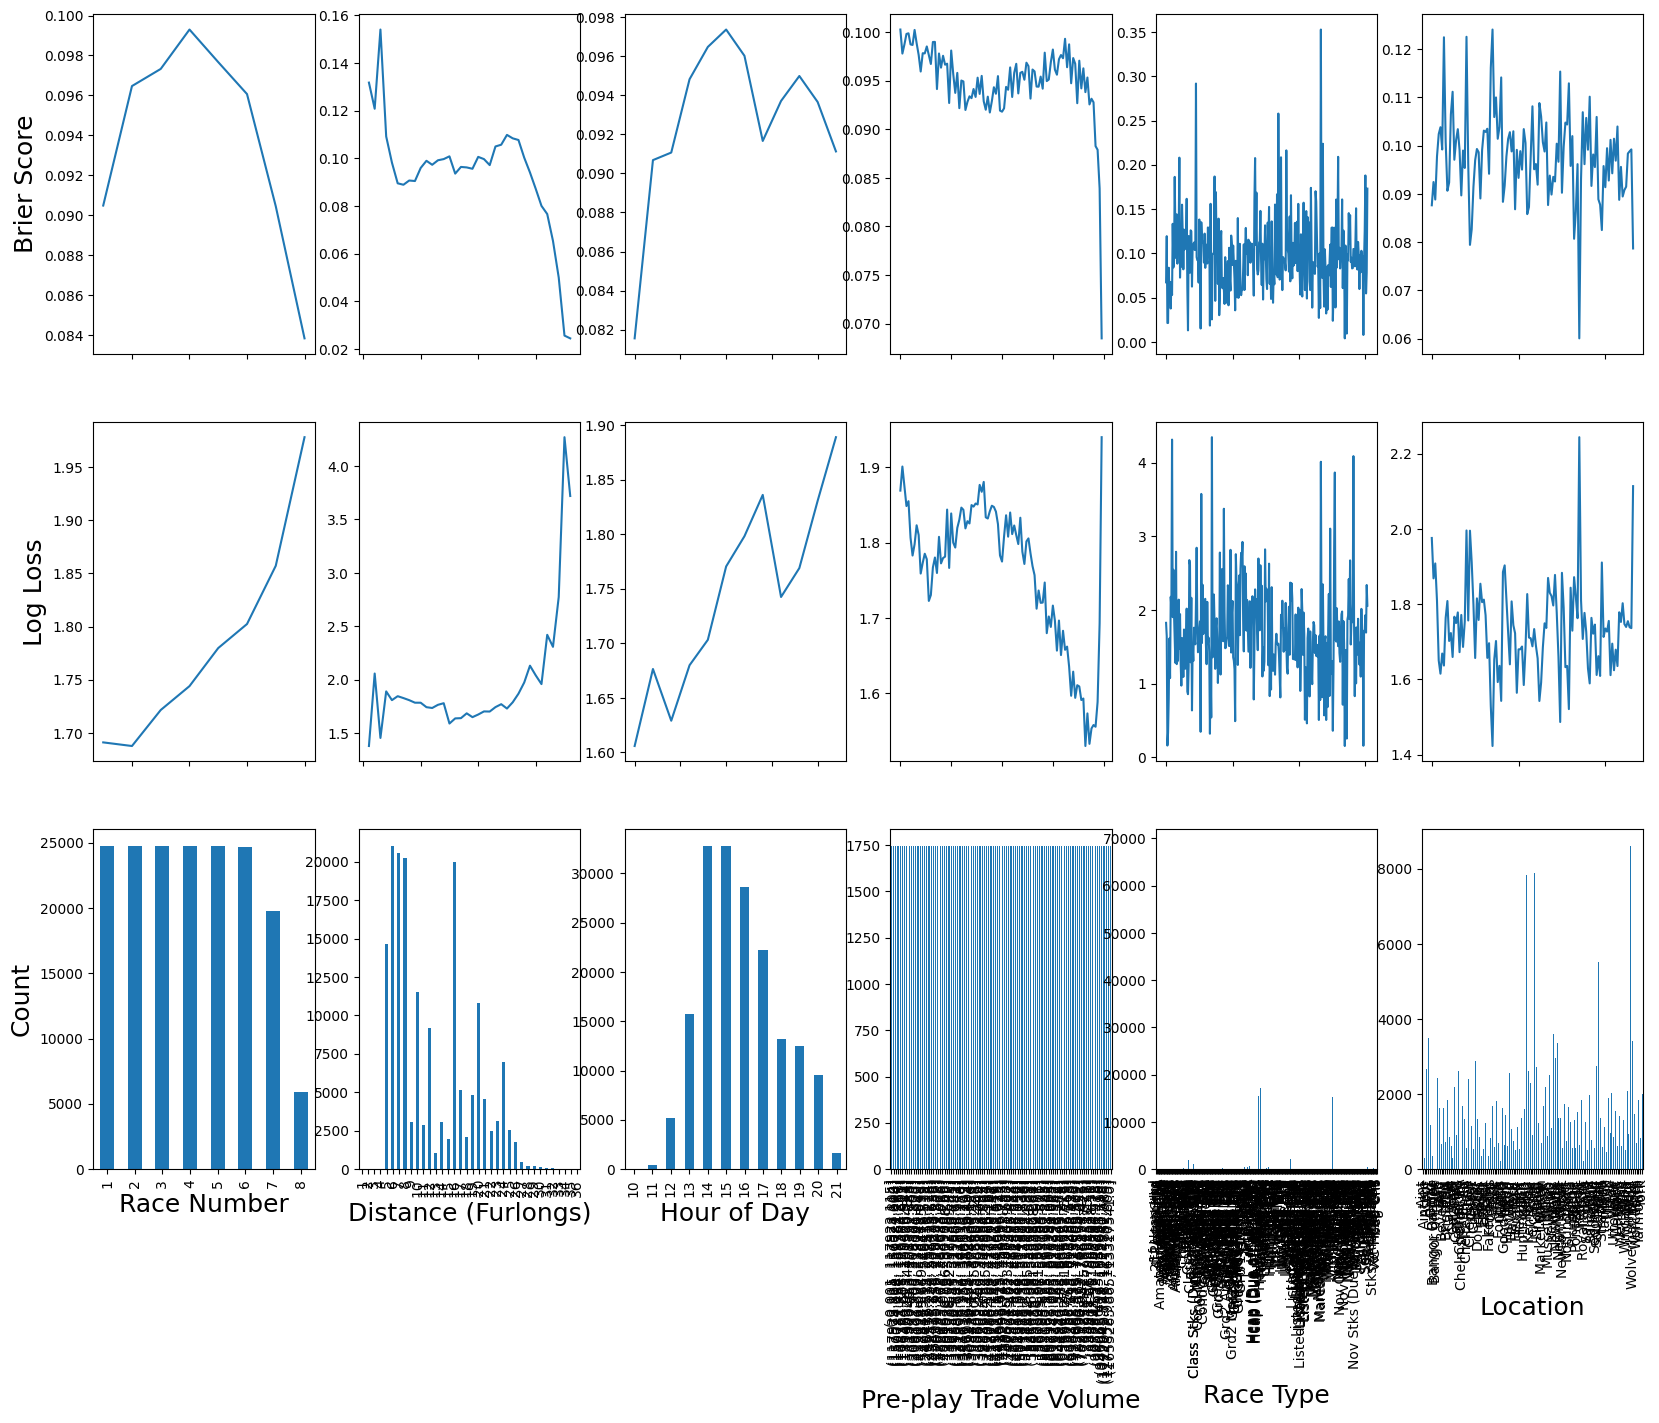

In [107]:
fig, axs = plt.subplots(3, len(categories), figsize=(20,15))
for i, (label, c) in enumerate(categories):
    c.brier.mean().plot(ax=axs[0][i], sharex=True)
    c.log_loss.mean().plot(ax=axs[1][i])
    c.race_type.count().plot.bar(ax=axs[2][i])
    axs[2][i].set_xlabel(label, fontsize=18)

mid = (len(categories))//2
axs[0][0].set_ylabel("Brier Score", fontsize=18)
axs[1][0].set_ylabel("Log Loss", fontsize=18)
axs[2][0].set_ylabel("Count", fontsize=18)

In [46]:
races

,race_type,race_time,distance_f,event_id,race_no,brier,log_loss
race_id,,,,,,,
162764294,Hcap,2019-09-24 15:05:00,7,1824,3,0.068071,1.674460
162764320,Hcap,2019-09-24 17:45:00,10,1824,8,0.058975,1.408923
162764284,Nov Stks,2019-09-24 14:00:00,5,1824,1,0.108947,1.838070
162764331,Nov Stks,2019-09-24 17:25:00,7,3516,2,0.058530,1.352450
162764361,Hcap,2019-09-24 20:30:00,14,3516,8,0.055623,0.752975
...,...,...,...,...,...,...,...
186160695,Nov Stks,2021-08-09 15:35:00,7,896,4,0.078881,1.481178
186161070,Hcap,2021-08-09 19:55:00,5,17352,5,0.112807,0.844441
186161164,App Hcap,2021-08-09 17:35:00,6,22091,2,0.156905,2.298789


In [105]:
runners

,race_id,selection_name,win_lose,bsp,implied_odds,ppwap,morningwap,ppmax,ppmin,ipmax,ipmin,morningtradedvol,pptradedvol,iptradedvol,normalised_odds,brier,log_loss
selection_id,,,,,,,,,,,,,,,,,
8709395,162764294,Zylan,False,23.000000,0.043478,18.397112,10.189857,22.00,9.24,1000.0,12.00,642.739990,13388.459961,1743.660034,0.043186,0.001865,0.0
20377712,162764320,Major Snugfit,False,7.837297,0.127595,7.288927,7.290506,9.40,6.00,1000.0,2.90,1088.199951,58811.339844,7166.410156,0.127547,0.016268,0.0
24209475,162764284,Bosuns Chair,False,150.000000,0.006667,156.691589,90.800003,300.00,42.00,1000.0,21.00,65.540001,2000.260010,508.010010,0.006716,0.000045,0.0
24209478,162764284,Dancinginthesand,False,32.000000,0.031250,24.183567,22.995310,34.00,19.50,1000.0,8.60,277.100006,6302.540039,1921.500000,0.031480,0.000991,0.0
24148082,162764331,Taamer,False,6.200000,0.161290,7.027211,8.440805,9.60,5.80,1000.0,4.30,631.780029,32564.160156,4578.720215,0.160903,0.025890,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40484789,186161169,Alyas Gold Award,False,7.380804,0.135487,7.965647,6.534649,10.50,7.00,1000.0,7.20,615.000000,33865.320312,4295.209961,0.134142,0.017994,0.0
40262716,186161169,Dansemai,False,17.441746,0.057334,19.368006,40.297195,37.57,16.50,1000.0,5.50,24.900000,10423.820312,2537.709961,0.056765,0.003222,0.0
35415057,186161205,Chase That Dream,False,4.963830,0.201457,3.770604,3.324620,5.60,3.00,1000.0,3.65,18485.019531,115489.703125,5235.740234,0.198716,0.039488,0.0
